# 05 — Model comparison

**Objective.** Compare all models on the held-out test set: macro-F1, per-class results, confusion matrix, calibration and per-language fairness.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (9, 4)
from ml.config import PROCESSED_DATASET, ARTIFACTS_DIR, METADATA_DIR, RAW_DIR
df = pd.read_csv(PROCESSED_DATASET)
print(f'{len(df):,} processed fact-checks')

4,137 processed fact-checks


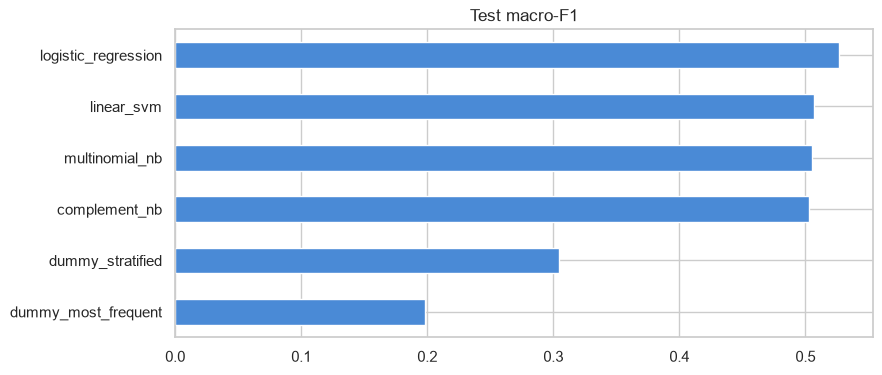

,accuracy,f1_macro,f1_weighted,precision_macro,recall_macro
dummy_most_frequent,0.422,0.198,0.250,0.141,0.333
dummy_stratified,0.339,0.305,0.334,0.306,0.306
multinomial_nb,0.534,0.505,0.526,0.529,0.507
complement_nb,0.541,0.503,0.529,0.550,0.502
logistic_regression,0.555,0.527,0.551,0.534,0.524
linear_svm,0.574,0.506,0.549,0.606,0.509


In [2]:
meta = json.loads((ARTIFACTS_DIR / 'classifier_metadata.json').read_text())
comp = pd.DataFrame({k: {m: v['test'][m] for m in ('accuracy','f1_macro','f1_weighted','precision_macro','recall_macro')} for k, v in meta['results'].items()}).T
ax = comp['f1_macro'].sort_values().plot.barh(color='#4a8ad6'); ax.set_title('Test macro-F1'); plt.show(); comp.round(3)

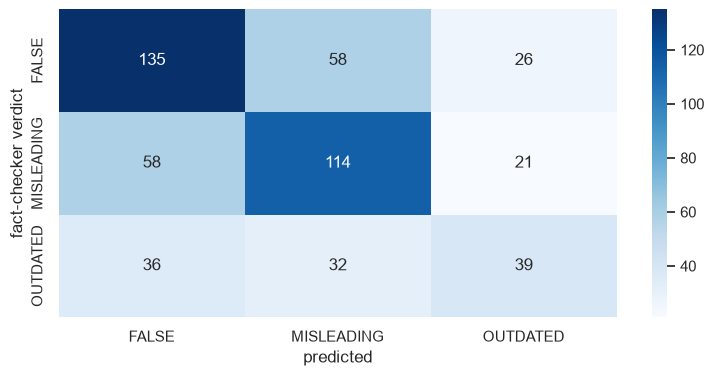

,precision,recall,f1,support
FALSE,0.5895,0.6164,0.6027,219.0
MISLEADING,0.5588,0.5907,0.5743,193.0
OUTDATED,0.4535,0.3645,0.4041,107.0


In [3]:
dep = meta['results'][meta['deployed_model']]['test']
cm = pd.DataFrame(dep['confusion_matrix']['matrix'], index=dep['confusion_matrix']['labels'], columns=dep['confusion_matrix']['labels'])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues'); plt.ylabel('fact-checker verdict'); plt.xlabel('predicted'); plt.show()
pd.DataFrame(dep['per_class']).T

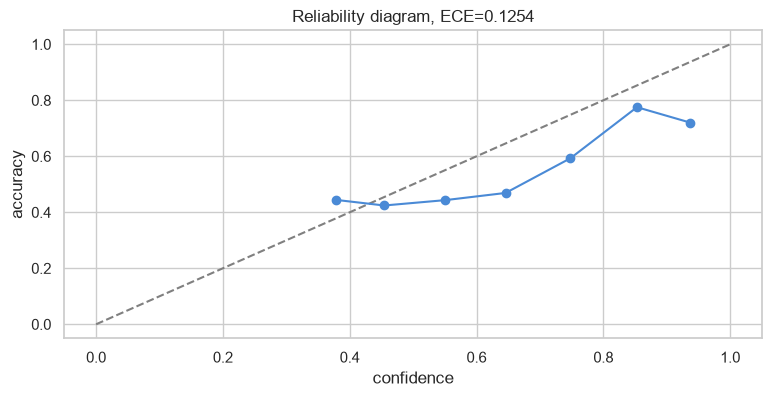

In [4]:
cal = pd.DataFrame(dep['calibration']['bins'])
plt.plot([0,1],[0,1],'--',color='grey'); plt.plot(cal.avg_confidence, cal.accuracy, 'o-', color='#4a8ad6'); plt.xlabel('confidence'); plt.ylabel('accuracy'); plt.title(f"Reliability diagram, ECE={dep['calibration']['ece']}"); plt.show()

In [5]:
pd.DataFrame({f'{c}={k}': v for c, parts in meta['deployed_breakdown_test'].items() for k, v in parts.items()}).T[['n','f1_macro','accuracy']]

,n,f1_macro,accuracy
language=en,299,0.4907,0.5619
language=hi,119,0.5002,0.5462
language=kn,101,0.458,0.5446
claim_source=claim_field,247,0.525,0.5749
claim_source=title,272,0.5113,0.5368


## Observations
* OUTDATED has the lowest recall: whether a video is old is rarely visible in the claim's wording.
* Kannada scores lowest of the three languages.
* Confidence is moderately calibrated; the UI therefore shows probabilities but never treats them as truth.

**Conclusion.** The classifier is a weak signal (20% weight in the risk index); evidence retrieval must dominate.